# Haryana Mandi Insights
## Agricultural Price Analysis and Forecasting
### Notebook 3 — Statistical Analysis

---

**Course:** Advanced Data Science
**Dataset:** Haryana Mandi Agricultural Price Data (2022–2026)
**Input:** Haryana_Mandi_Cleaned.csv (output of Notebook 1)


## Statistical Analysis Objectives

| Section | Analysis |
|---|---|
| 1 | Statistical summary — descriptive statistics |
| 2 | Time series analysis — decomposition, stationarity, ACF/PACF |
| 3 | Hypothesis H1 — Market price difference (ANOVA) |
| 4 | Hypothesis H2 — Seasonal price difference (ANOVA) |
| 5 | Correlation analysis — Pearson and Spearman |
| 6 | Year-over-year price change |
| 7 | Inter-market price divergence |
| 8 | Hypothesis scorecard |
| 9 | Final statistical conclusions |

---

## Hypotheses

| # | H0 | H1 |
|---|---|---|
| H1 | Modal prices do not differ significantly across markets | At least one market has a significantly different modal price |
| H2 | Modal prices do not differ significantly across seasons | At least one season has a significantly different modal price |
| H3 | ML models do not outperform a naive baseline | ML models produce lower RMSE than the naive baseline |

**Significance level: α = 0.05**

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted")

Mounted at /content/drive
Google Drive mounted


In [2]:
# Install Libraries
!pip install statsmodels --quiet
!pip install scipy --quiet
print("Libraries installed")

Libraries installed


In [4]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from scipy import stats
from scipy.stats import (f_oneway, kruskal, levene,
                          shapiro, pearsonr, spearmanr)
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import itertools
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
#  Define Paths
BASE_PATH      = '/content/drive/MyDrive/Haryana_Mandi_Project/'
PROCESSED_PATH = BASE_PATH + 'Data/Processed/'
IMAGES_STAT    = BASE_PATH + 'Images/Statistical/'
REPORTS_PATH   = BASE_PATH + 'Reports/'

import os
for path in [PROCESSED_PATH, IMAGES_STAT, REPORTS_PATH]:
    os.makedirs(path, exist_ok=True)

print("Paths defined")

Paths defined


In [6]:
# Load Cleaned Dataset
df = pd.read_csv(PROCESSED_PATH + 'Haryana_Mandi_Cleaned.csv',
                 parse_dates=['Arrival_Date'])

print("═"*55)
print("         DATASET OVERVIEW")
print("═"*55)
print(f"Shape              : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date Range         : {df['Arrival_Date'].min().date()} "
      f"→ {df['Arrival_Date'].max().date()}")
print(f"Districts          : {sorted(df['District'].unique())}")
print(f"Unique Markets     : {df['Market'].nunique()}")
print(f"Unique Commodities : {df['Commodity'].nunique()}")
print("═"*55)
df.head(3)

═══════════════════════════════════════════════════════
         DATASET OVERVIEW
═══════════════════════════════════════════════════════
Shape              : 133,720 rows × 20 columns
Date Range         : 2022-08-01 → 2026-07-31
Districts          : ['Hissar', 'Jind', 'Kaithal', 'Karnal', 'Rewari', 'Sirsa']
Unique Markets     : 95
Unique Commodities : 104
═══════════════════════════════════════════════════════


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
0,2023-04-26,Mustard,12,Hissar,FAQ,Adampur,5450,4381.0000,4650.0000,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,1069.0000,False
1,2023-04-28,Mustard,12,Hissar,FAQ,Adampur,4890,4011.0000,4664.0000,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,879.0000,False
2,2023-05-02,Mustard,12,Hissar,FAQ,Adampur,4899,4151.0000,4500.0000,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,18,Zaid,748.0000,False


## Section 1 — Statistical Summary

We compute full descriptive statistics for the Modal Price column
and for each of the top commodities individually.

Statistics computed:
- Mean, Median, Mode
- Standard Deviation, Variance
- Min, Max, Quartiles
- Coefficient of Variation (CV%)
- Skewness
- Kurtosis

In [7]:
# Overall Statistical Summary
price = df['Modal_Price'].dropna()

print("═"*55)
print("    MODAL PRICE — OVERALL STATISTICAL SUMMARY")
print("═"*55)
print(f"Count              : {len(price):,}")
print(f"Mean               : ₹{price.mean():,.2f}")
print(f"Median             : ₹{price.median():,.2f}")
print(f"Mode               : ₹{price.mode()[0]:,.2f}")
print(f"Std Deviation      : ₹{price.std():,.2f}")
print(f"Variance           : ₹{price.var():,.2f}")
print(f"Min                : ₹{price.min():,.2f}")
print(f"Max                : ₹{price.max():,.2f}")
print(f"Q1 (25th pct)      : ₹{price.quantile(0.25):,.2f}")
print(f"Q2 (50th pct)      : ₹{price.quantile(0.50):,.2f}")
print(f"Q3 (75th pct)      : ₹{price.quantile(0.75):,.2f}")
print(f"IQR                : ₹{price.quantile(0.75) - price.quantile(0.25):,.2f}")
print(f"CV%                : {(price.std()/price.mean())*100:.2f}%")
print(f"Skewness           : {price.skew():.4f}")
print(f"Kurtosis           : {price.kurtosis():.4f}")
print("═"*55)
print("""
Interpretation:
- Positive skewness indicates a right-skewed distribution —
  a small number of high-value commodities pull the mean above
  the median.
- High kurtosis suggests heavy tails — more extreme price
  observations than a normal distribution would produce.
""")

═══════════════════════════════════════════════════════
    MODAL PRICE — OVERALL STATISTICAL SUMMARY
═══════════════════════════════════════════════════════
Count              : 133,720
Mean               : ₹3,085.47
Median             : ₹2,030.00
Mode               : ₹2,000.00
Std Deviation      : ₹2,819.98
Variance           : ₹7,952,291.80
Min                : ₹0.15
Max                : ₹200,000.00
Q1 (25th pct)      : ₹1,250.00
Q2 (50th pct)      : ₹2,030.00
Q3 (75th pct)      : ₹4,000.00
IQR                : ₹2,750.00
CV%                : 91.40%
Skewness           : 4.6642
Kurtosis           : 184.0907
═══════════════════════════════════════════════════════

Interpretation:
- Positive skewness indicates a right-skewed distribution —
  a small number of high-value commodities pull the mean above
  the median.
- High kurtosis suggests heavy tails — more extreme price
  observations than a normal distribution would produce.



In [8]:
# Commodity-wise Statistical Summary
top10 = df['Commodity'].value_counts().head(10).index.tolist()

stat_summary = df[df['Commodity'].isin(top10)]\
    .groupby('Commodity')['Modal_Price']\
    .agg(
        Count    = 'count',
        Mean     = 'mean',
        Median   = 'median',
        Std      = 'std',
        Variance = 'var',
        Min      = 'min',
        Max      = 'max',
        Q1       = lambda x: x.quantile(0.25),
        Q3       = lambda x: x.quantile(0.75),
        Skew     = 'skew',
        Kurt     = lambda x: x.kurtosis()
    ).round(2).reset_index()

stat_summary['CV_%'] = (
    (stat_summary['Std'] / stat_summary['Mean']) * 100
).round(2)

stat_summary['IQR'] = (stat_summary['Q3'] - stat_summary['Q1']).round(2)

print("Commodity-wise Statistical Summary — Top 10 Commodities:")
print(stat_summary.to_string(index=False))

Commodity-wise Statistical Summary — Top 10 Commodities:
       Commodity  Count      Mean    Median       Std      Variance       Min        Max        Q1         Q3    Skew    Kurt    CV_%       IQR
           Apple   7289 8211.2800 7900.0000 3501.8700 12263110.7900 1000.0000 25000.0000 5500.0000 10000.0000  1.0200  1.1800 42.6500 4500.0000
          Banana   7214 2369.0600 2050.0000  717.5300   514851.0400 1000.0000  6500.0000 1800.0000  3000.0000  0.7900 -0.0600 30.2900 1200.0000
    Bottle gourd   3885 1323.0300 1200.0000  601.4800   361775.4900  250.0000  5500.0000  900.0000  1700.0000  1.1100  2.0600 45.4600  800.0000
         Brinjal   4070 1411.2900 1350.0000  551.6300   304293.4800  250.0000  4300.0000 1000.0000  1800.0000  1.0200  1.9100 39.0900  800.0000
     Cauliflower   3792 1874.9300 1500.0000 1307.3000  1709042.3000  150.0000  9000.0000  842.5000  2750.0000  1.0800  0.7900 69.7300 1907.5000
          Cotton   4156 7111.5400 7125.0000  696.4500   485041.3600 4100.0000 1

## Section 2 — Time Series Analysis

Time series analysis decomposes the price series into:
- **Trend** — long-term direction of prices
- **Seasonality** — recurring patterns within a year
- **Residual** — random noise after removing trend and seasonality

We also test for **stationarity** using the Augmented Dickey-Fuller
(ADF) test, which is required before applying forecasting models.

### ADF Test Hypotheses
- **H0:** The series has a unit root (non-stationary)
- **H1:** The series is stationary
- **Decision rule:** If p-value < 0.05, reject H0 → series is stationary

In [9]:
# Monthly Aggregation
monthly_df = df.groupby(
    ['Commodity', pd.Grouper(key='Arrival_Date', freq='ME')]
)['Modal_Price'].mean().reset_index()

monthly_df.rename(columns={'Arrival_Date': 'Month'}, inplace=True)
monthly_df['Month'] = monthly_df['Month'].dt.to_period('M')

print(f"Monthly aggregated records : {len(monthly_df):,}")
print(monthly_df.head(8))

Monthly aggregated records : 2,499
         Commodity    Month  Modal_Price
0  Amla(Nelli Kai)  2023-09    3630.0000
1  Amla(Nelli Kai)  2024-04    1200.0000
2  Amla(Nelli Kai)  2024-05    1400.0000
3            Apple  2022-08    5603.5354
4            Apple  2022-09    5136.4198
5            Apple  2022-10    4275.3521
6            Apple  2022-11    4397.0297
7            Apple  2022-12    4844.3038


In [13]:
# Build Time Series
COMMODITY = 'Wheat'

ts = monthly_df[monthly_df['Commodity'] == COMMODITY]\
         .sort_values('Month').copy()
ts.index = ts['Month'].dt.to_timestamp()
ts = ts['Modal_Price']

print(f"Commodity     : {COMMODITY}")
print(f"Time range    : {ts.index.min().date()} → {ts.index.max().date()}")
print(f"Monthly points: {len(ts)}")
print(f"\nMissing months: {pd.date_range(ts.index.min(), ts.index.max(), freq='MS').difference(ts.index).shape[0]}")
print(ts)

Commodity     : Wheat
Time range    : 2023-04-01 → 2026-05-01
Monthly points: 19

Missing months: 19
Month
2023-04-01   2125.5217
2023-05-01   2134.9262
2023-06-01   2209.8333
2023-09-01   2123.0000
2024-01-01   2300.0000
2024-04-01   2275.2520
2024-05-01   2275.3643
2024-06-01   2313.3333
2024-07-01   2413.3333
2024-09-01   2515.0000
2024-10-01   2680.0000
2024-11-01   2785.0000
2025-03-01   2500.0000
2025-04-01   2425.6723
2025-05-01   2426.2654
2025-06-01   2412.0000
2025-09-01   2500.0000
2026-04-01   2585.0346
2026-05-01   2583.3942
Name: Modal_Price, dtype: float64


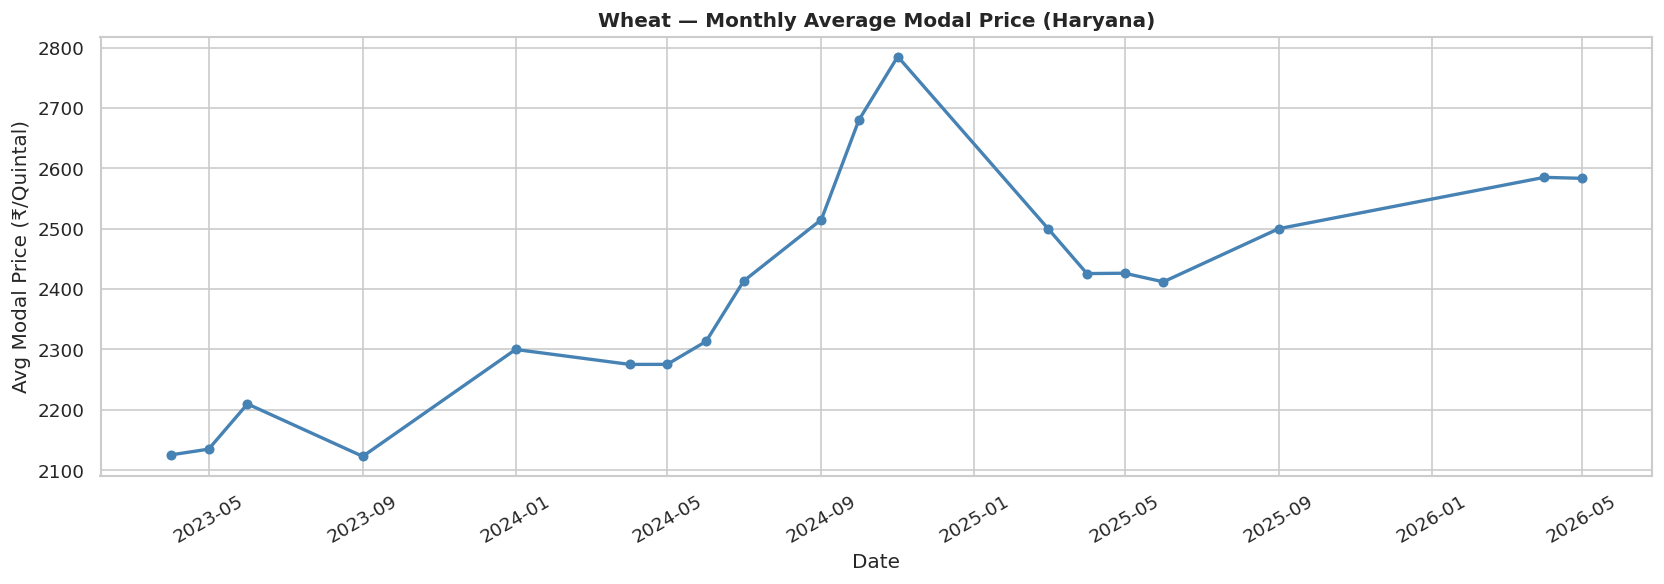


Interpretation:
The Wheat price series shows the overall trend over the
observation period. Visual inspection helps identify whether
prices are generally increasing, decreasing or stable, and
whether seasonal patterns are present.



In [14]:
# Raw Time Series Plot
plt.figure(figsize=(14, 5))
plt.plot(ts.index, ts.values, color='steelblue',
         linewidth=2, marker='o', markersize=5)
plt.title(f'{COMMODITY} — Monthly Average Modal Price (Haryana)',
          fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(IMAGES_STAT + f'stat_{COMMODITY}_raw_ts.png',
            bbox_inches='tight')
plt.show()

print(f"""
Interpretation:
The {COMMODITY} price series shows the overall trend over the
observation period. Visual inspection helps identify whether
prices are generally increasing, decreasing or stable, and
whether seasonal patterns are present.
""")

Observations available : 19
Using period = 6 (Semi-Annual (period=6))


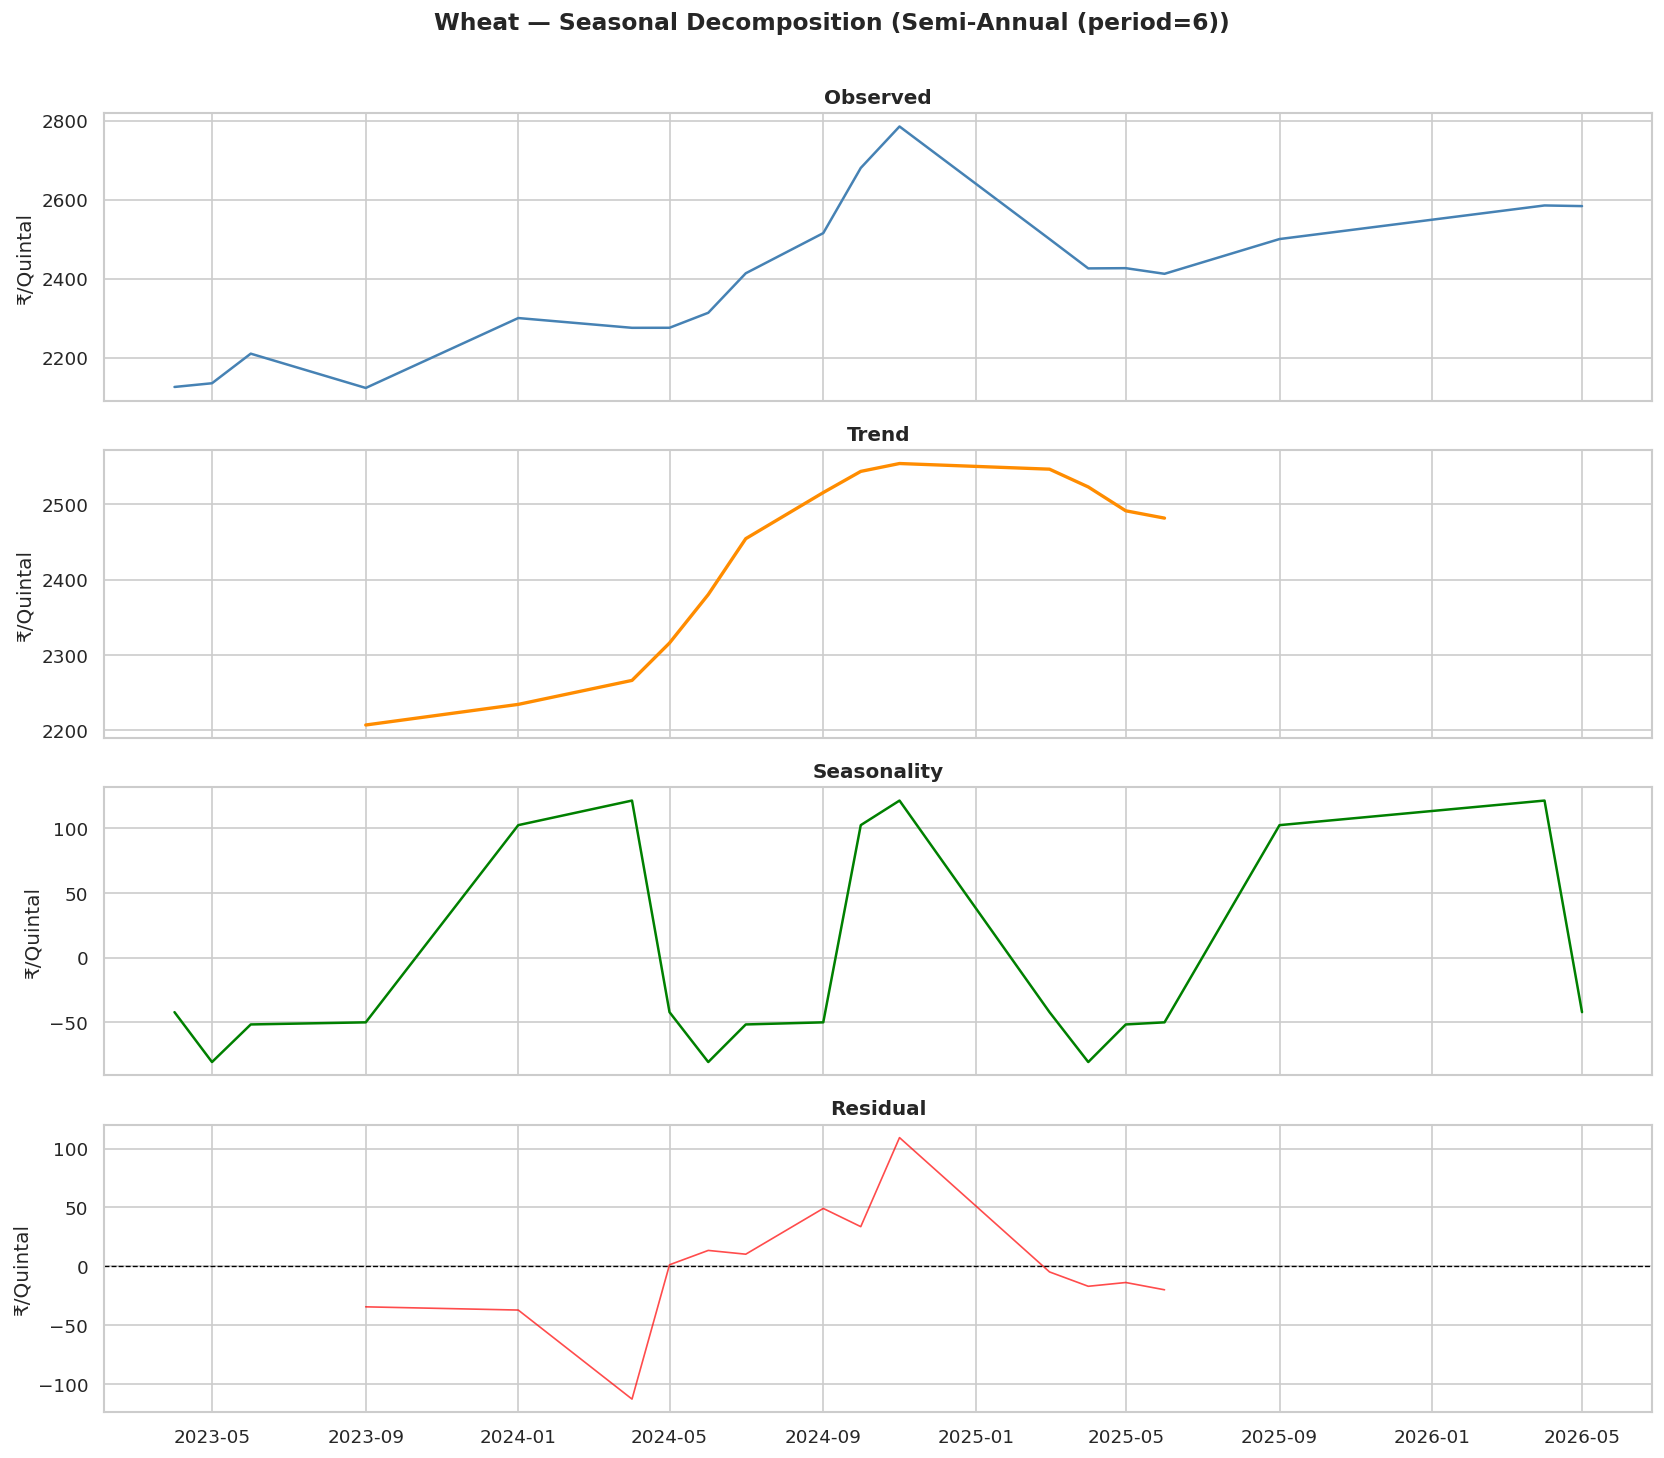


Interpretation:
- Trend component: Shows the long-term price direction.
- Seasonal component: Reveals repeating annual patterns.
- Residual component: Random noise after removing trend
  and seasonality. Residuals should be near zero with
  no pattern if the decomposition is complete.



In [15]:
# Seasonal Decomposition
n_obs = len(ts.dropna())
print(f"Observations available : {n_obs}")

if n_obs >= 24:
    period       = 12
    period_label = 'Annual (period=12)'
elif n_obs >= 12:
    period       = 6
    period_label = 'Semi-Annual (period=6)'
else:
    print("Not enough data points for decomposition.")
    raise SystemExit

print(f"Using period = {period} ({period_label})")

decomp = seasonal_decompose(ts.dropna(),
                             model='additive', period=period)

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(decomp.observed,  color='steelblue',  linewidth=1.5)
axes[0].set_title('Observed',    fontweight='bold')
axes[0].set_ylabel('₹/Quintal')

axes[1].plot(decomp.trend,     color='darkorange', linewidth=2)
axes[1].set_title('Trend',       fontweight='bold')
axes[1].set_ylabel('₹/Quintal')

axes[2].plot(decomp.seasonal,  color='green',      linewidth=1.5)
axes[2].set_title('Seasonality', fontweight='bold')
axes[2].set_ylabel('₹/Quintal')

axes[3].plot(decomp.resid,     color='red',
             linewidth=1, alpha=0.7)
axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[3].set_title('Residual',    fontweight='bold')
axes[3].set_ylabel('₹/Quintal')

plt.suptitle(f'{COMMODITY} — Seasonal Decomposition ({period_label})',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(IMAGES_STAT + f'stat_{COMMODITY}_decomposition.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
- Trend component: Shows the long-term price direction.
- Seasonal component: Reveals repeating annual patterns.
- Residual component: Random noise after removing trend
  and seasonality. Residuals should be near zero with
  no pattern if the decomposition is complete.
""")

In [17]:
# ADF Stationarity Test
def adf_test(series, name='Series'):
    result = adfuller(series.dropna())
    print(f"{'─'*50}")
    print(f"ADF Test — {name}")
    print(f"{'─'*50}")
    print(f"ADF Statistic  : {result[0]:.4f}")
    print(f"p-value        : {result[1]:.4f}")
    print(f"Lags Used      : {result[2]}")
    print(f"Observations   : {result[3]}")
    print(f"Critical Values:")
    for key, val in result[4].items():
        print(f"   {key}  :  {val:.4f}")
    if result[1] < 0.05:
        print(f"STATIONARY — Reject H0 (p < 0.05)")
    else:
        print(f"NON-STATIONARY — Fail to reject H0 (p ≥ 0.05)")
        print(f"   → First differencing required")
    print()
    return result[1]

# Test original series
p1 = adf_test(ts, name=f'{COMMODITY} — Original Series')

# First differencing
ts_diff = ts.diff().dropna()
p2 = adf_test(ts_diff, name=f'{COMMODITY} — First Differenced Series')

──────────────────────────────────────────────────
ADF Test — Wheat — Original Series
──────────────────────────────────────────────────
ADF Statistic  : -1.6793
p-value        : 0.4418
Lags Used      : 1
Observations   : 17
Critical Values:
   1%  :  -3.8893
   5%  :  -3.0544
   10%  :  -2.6670
NON-STATIONARY — Fail to reject H0 (p ≥ 0.05)
   → First differencing required

──────────────────────────────────────────────────
ADF Test — Wheat — First Differenced Series
──────────────────────────────────────────────────
ADF Statistic  : -30.8013
p-value        : 0.0000
Lags Used      : 7
Observations   : 10
Critical Values:
   1%  :  -4.3316
   5%  :  -3.2330
   10%  :  -2.7487
STATIONARY — Reject H0 (p < 0.05)



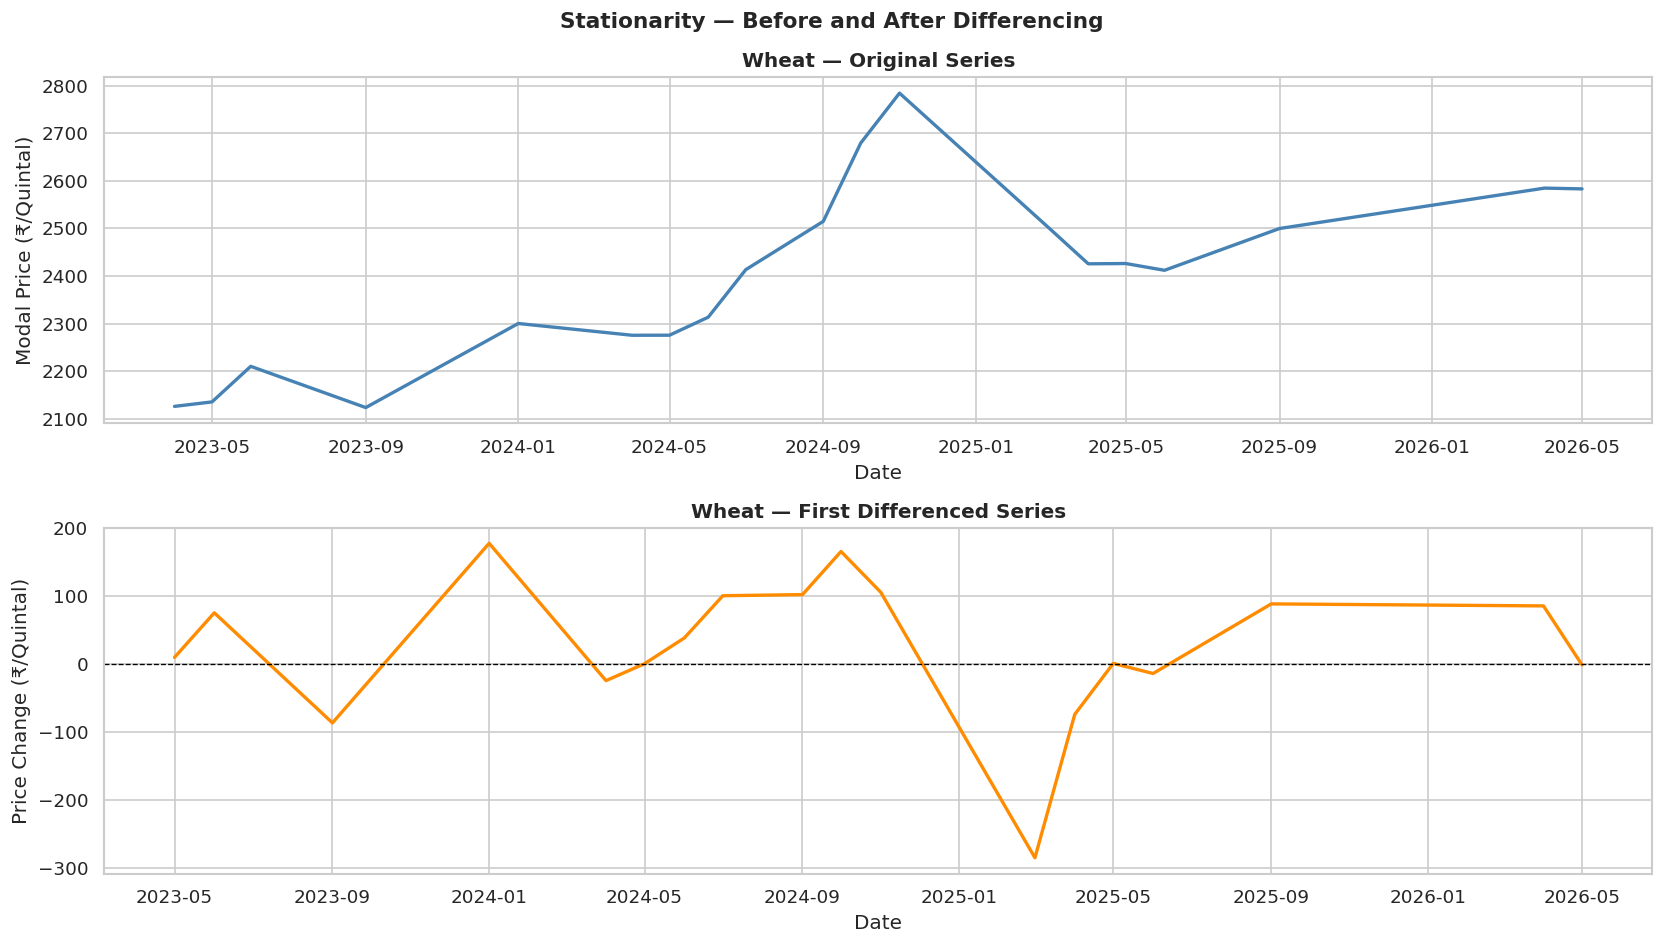

In [18]:
# Before and After Differencing
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(ts.index, ts.values, color='steelblue', linewidth=2)
axes[0].set_title(f'{COMMODITY} — Original Series',
                   fontweight='bold')
axes[0].set_ylabel('Modal Price (₹/Quintal)')
axes[0].set_xlabel('Date')

axes[1].plot(ts_diff.index, ts_diff.values,
             color='darkorange', linewidth=2)
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title(f'{COMMODITY} — First Differenced Series',
                   fontweight='bold')
axes[1].set_ylabel('Price Change (₹/Quintal)')
axes[1].set_xlabel('Date')

plt.suptitle('Stationarity — Before and After Differencing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_STAT + f'stat_{COMMODITY}_differencing.png',
            bbox_inches='tight')
plt.show()

Observations : 19
Using lags   : 8


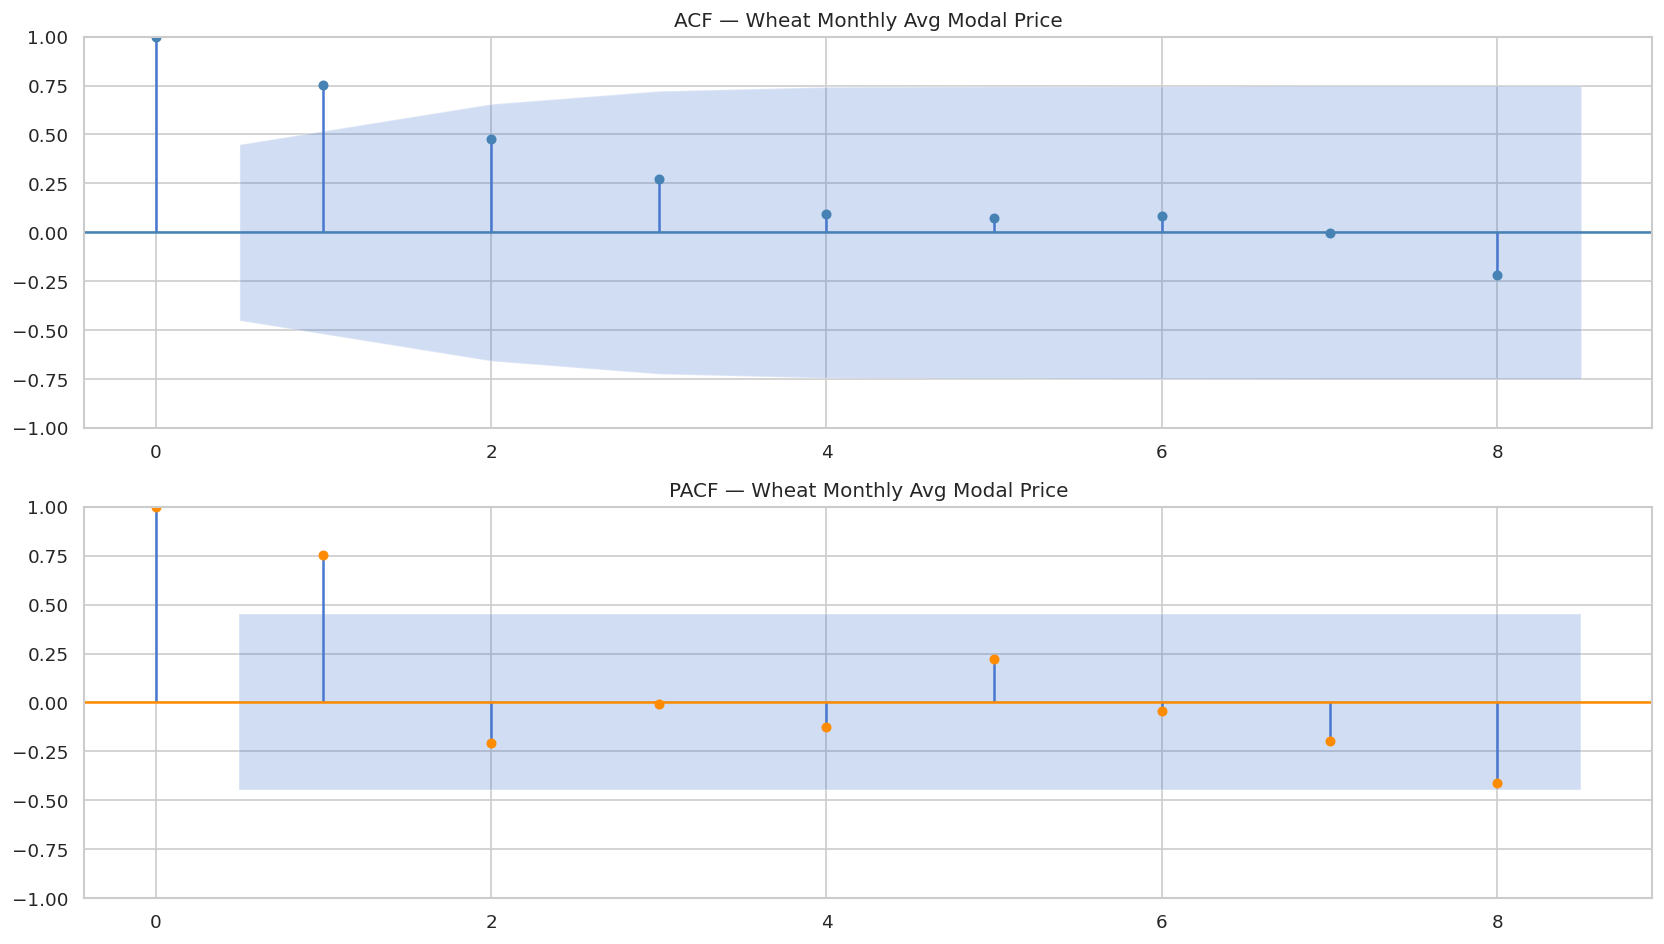


Interpretation:
- ACF (Autocorrelation Function): Shows correlation between
  the series and its lagged values. Significant spikes at
  lag k indicate a moving average (MA) component of order k.
- PACF (Partial Autocorrelation Function): Shows the direct
  correlation at each lag after removing intermediate effects.
  Significant spikes indicate an autoregressive (AR) component.
- These plots guide the selection of ARIMA model parameters.



In [19]:
# ACF and PACF Plots
n_obs    = len(ts.dropna())
max_lags = min(24, n_obs // 2 - 1)
print(f"Observations : {n_obs}")
print(f"Using lags   : {max_lags}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(ts.dropna(), lags=max_lags, ax=axes[0],
         color='steelblue',
         title=f'ACF — {COMMODITY} Monthly Avg Modal Price')

plot_pacf(ts.dropna(), lags=max_lags, ax=axes[1],
          color='darkorange',
          title=f'PACF — {COMMODITY} Monthly Avg Modal Price')

plt.tight_layout()
plt.savefig(IMAGES_STAT + f'stat_{COMMODITY}_acf_pacf.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
- ACF (Autocorrelation Function): Shows correlation between
  the series and its lagged values. Significant spikes at
  lag k indicate a moving average (MA) component of order k.
- PACF (Partial Autocorrelation Function): Shows the direct
  correlation at each lag after removing intermediate effects.
  Significant spikes indicate an autoregressive (AR) component.
- These plots guide the selection of ARIMA model parameters.
""")

## Section 3 — Hypothesis H1: Market Price Difference

### Research Question
Do modal prices differ significantly across selected markets
for the same commodity?

### Hypotheses
- **H0:** There is no statistically significant difference in
  modal prices across selected markets for Wheat
- **H1:** At least one market has a significantly different
  modal price from the others

### Tests Applied
1. Shapiro-Wilk test — normality check
2. Levene's test — homogeneity of variance
3. One-way ANOVA — parametric test
4. Kruskal-Wallis — non-parametric alternative
5. Post-hoc pairwise comparisons (Tukey HSD)
6. Effect size (Eta-squared)

**Significance level: α = 0.05**
**Commodity: Wheat**

In [20]:
# Prepare Data for H1
H1_COMMODITY = 'Wheat'

# Select top markets with sufficient records
market_counts = df[df['Commodity'] == H1_COMMODITY]\
                   ['Market'].value_counts()
top_markets   = market_counts[market_counts >= 30].head(6).index.tolist()

h1_data = df[
    (df['Commodity'] == H1_COMMODITY) &
    (df['Market'].isin(top_markets))
][['Market', 'Modal_Price']].dropna()

print(f"Commodity     : {H1_COMMODITY}")
print(f"Markets       : {top_markets}")
print(f"\nRecords per market:")
print(h1_data['Market'].value_counts())
print(f"\nDescriptive Statistics per Market:")
print(h1_data.groupby('Market')['Modal_Price'].agg(
    ['count','mean','median','std']
).round(2))

Commodity     : Wheat
Markets       : ['Jullana', 'New Grain Market , Sirsa', 'Hissar', 'Uchana', 'Safidon', 'Hansi']

Records per market:
Market
Jullana                     59
New Grain Market , Sirsa    57
Hissar                      56
Safidon                     55
Uchana                      55
Hansi                       53
Name: count, dtype: int64

Descriptive Statistics per Market:
                          count      mean    median      std
Market                                                      
Hansi                        53 2273.7400 2275.0000 128.7900
Hissar                       56 2293.7500 2292.5000 132.3400
Jullana                      59 2286.7800 2275.0000 125.2400
New Grain Market , Sirsa     57 2309.6700 2275.0000 117.2700
Safidon                      55 2272.8200 2275.0000 130.3100
Uchana                       55 2265.6000 2275.0000 118.8000


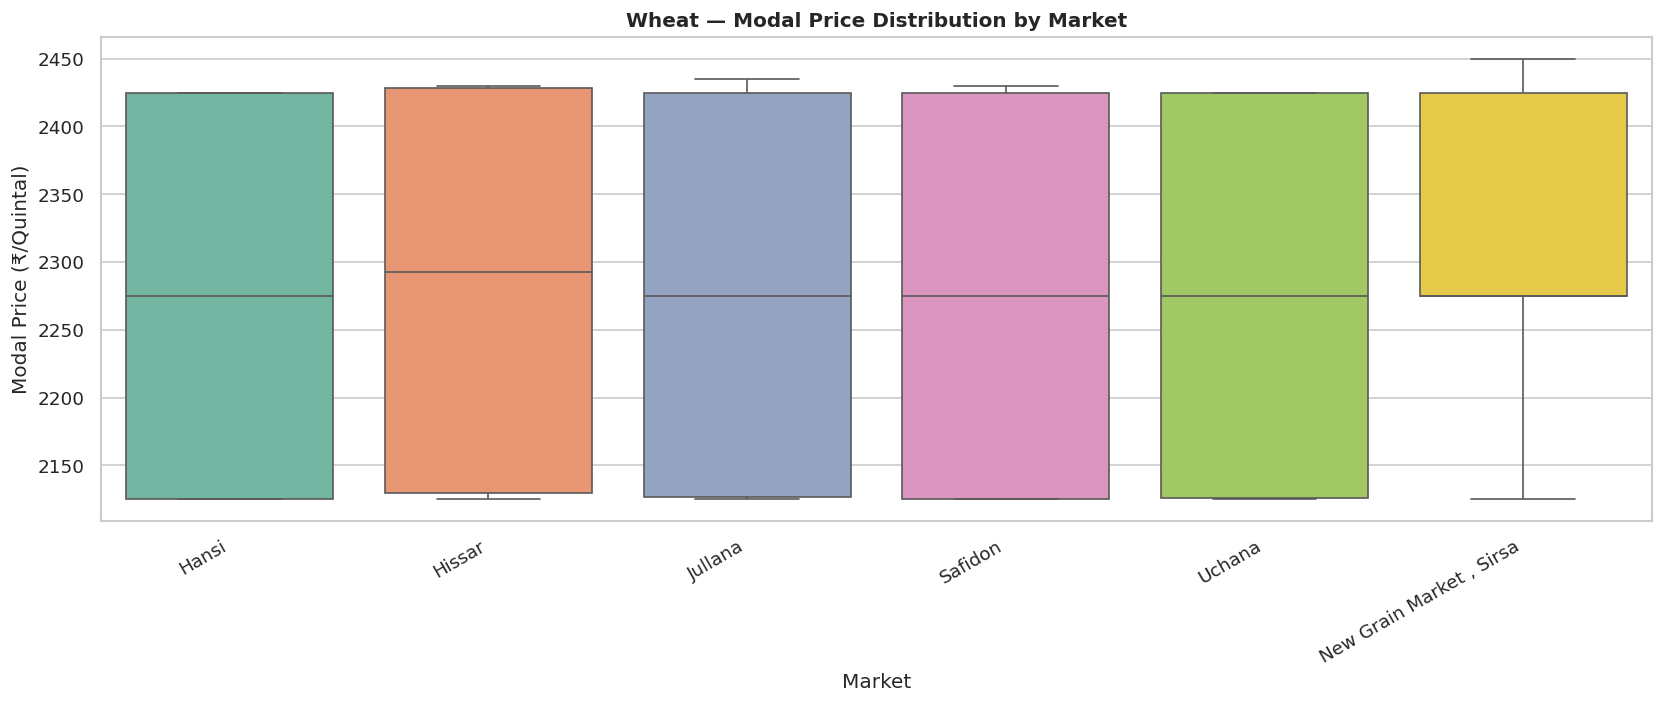

In [21]:
#  H1 — Market Price Distribution
plt.figure(figsize=(14, 6))
sns.boxplot(data=h1_data, x='Market', y='Modal_Price',
            palette='Set2',
            flierprops=dict(marker='o', markersize=3, alpha=0.4))
plt.title(f'{H1_COMMODITY} — Modal Price Distribution by Market',
          fontweight='bold')
plt.xlabel('Market')
plt.ylabel('Modal Price (₹/Quintal)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(IMAGES_STAT + 'stat_H1_market_boxplot.png',
            bbox_inches='tight')
plt.show()

In [22]:
# H1 — Normality Test (Shapiro-Wilk)
print("── Shapiro-Wilk Normality Test per Market ──")
print(f"{'Market':<25} {'Statistic':>12} {'p-value':>12} {'Normal?':>10}")
print("─"*62)

normality_results = {}
for market in top_markets:
    group  = h1_data[h1_data['Market'] == market]['Modal_Price']
    sample = group.sample(min(50, len(group)), random_state=42)
    stat, p = shapiro(sample)
    normal  = "Yes" if p > 0.05 else "No"
    normality_results[market] = p
    print(f"{market:<25} {stat:>12.4f} {p:>12.4f} {normal:>10}")

print("""
Note: Shapiro-Wilk is performed on a sample of up to 50 observations
per market. With large samples, even minor deviations from normality
become significant. The Kruskal-Wallis non-parametric test will be
used as a robust alternative regardless of normality.
""")

── Shapiro-Wilk Normality Test per Market ──
Market                       Statistic      p-value    Normal?
──────────────────────────────────────────────────────────────
Jullana                         0.7981       0.0000         No
New Grain Market , Sirsa        0.8010       0.0000         No
Hissar                          0.7554       0.0000         No
Uchana                          0.8280       0.0000         No
Safidon                         0.7767       0.0000         No
Hansi                           0.7882       0.0000         No

Note: Shapiro-Wilk is performed on a sample of up to 50 observations
per market. With large samples, even minor deviations from normality
become significant. The Kruskal-Wallis non-parametric test will be
used as a robust alternative regardless of normality.



In [24]:
#  H1 — Levene's Test for Homogeneity of Variance
groups = [h1_data[h1_data['Market'] == m]['Modal_Price'].values
          for m in top_markets]

lev_stat, lev_p = levene(*groups)

print("── Levene's Test for Homogeneity of Variance ──")
print(f"Levene Statistic : {lev_stat:.4f}")
print(f"p-value          : {lev_p:.4f}")
if lev_p > 0.05:
    print("Variances are EQUAL (p > 0.05) — ANOVA assumption met")
else:
    print("Variances are UNEQUAL (p ≤ 0.05) — Use Kruskal-Wallis")

── Levene's Test for Homogeneity of Variance ──
Levene Statistic : 0.9121
p-value          : 0.4733
Variances are EQUAL (p > 0.05) — ANOVA assumption met


In [27]:
# H1 — One-Way ANOVA
anova_stat, anova_p = f_oneway(*groups)

print("── One-Way ANOVA ──")
print(f"F-Statistic : {anova_stat:.4f}")
print(f"p-value     : {anova_p:.6f}")
print()
if anova_p < 0.05:
    print("REJECT H0 — Significant price difference across markets")
    print("   At least one market has a significantly different modal price")
else:
    print("FAIL TO REJECT H0 — No significant difference across markets")

── One-Way ANOVA ──
F-Statistic : 0.9444
p-value     : 0.452332

FAIL TO REJECT H0 — No significant difference across markets


In [29]:
#  H1 — Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*groups)

print("── Kruskal-Wallis Test (Non-Parametric Alternative) ──")
print(f"H-Statistic : {kw_stat:.4f}")
print(f"p-value     : {kw_p:.6f}")
print()
if kw_p < 0.05:
    print("REJECT H0 — Significant price difference across markets")
else:
    print("FAIL TO REJECT H0 — No significant difference")

── Kruskal-Wallis Test (Non-Parametric Alternative) ──
H-Statistic : 15.5970
p-value     : 0.008094

REJECT H0 — Significant price difference across markets


In [30]:
#  H1 — Effect Size and Post-hoc
# Eta-squared effect size
all_values  = np.concatenate(groups)
grand_mean  = all_values.mean()
ss_between  = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
ss_total    = sum((x - grand_mean)**2 for x in all_values)
eta_squared = ss_between / ss_total

print(f"Effect Size (Eta-squared) : {eta_squared:.4f}")
if eta_squared < 0.01:
    effect = "Negligible"
elif eta_squared < 0.06:
    effect = "Small"
elif eta_squared < 0.14:
    effect = "Medium"
else:
    effect = "Large"
print(f"Effect Size Interpretation: {effect}")
print()

# Confidence intervals per market
print("── 95% Confidence Intervals per Market ──")
print(f"{'Market':<25} {'Mean':>10} {'CI Lower':>12} {'CI Upper':>12}")
print("─"*62)
for market in top_markets:
    group = h1_data[h1_data['Market'] == market]['Modal_Price']
    mean  = group.mean()
    se    = stats.sem(group)
    ci    = stats.t.interval(0.95, len(group)-1, loc=mean, scale=se)
    print(f"{market:<25} {mean:>10.2f} {ci[0]:>12.2f} {ci[1]:>12.2f}")

Effect Size (Eta-squared) : 0.0141
Effect Size Interpretation: Small

── 95% Confidence Intervals per Market ──
Market                          Mean     CI Lower     CI Upper
──────────────────────────────────────────────────────────────
Jullana                      2286.78      2254.14      2319.42
New Grain Market , Sirsa     2309.67      2278.55      2340.78
Hissar                       2293.75      2258.31      2329.19
Uchana                       2265.60      2233.48      2297.72
Safidon                      2272.82      2237.59      2308.04
Hansi                        2273.74      2238.24      2309.23


In [31]:
# H1 — Tukey HSD Post-hoc
tukey = pairwise_tukeyhsd(
    endog  = h1_data['Modal_Price'],
    groups = h1_data['Market'],
    alpha  = 0.05
)
print("── Tukey HSD Post-hoc Pairwise Comparisons ──")
print(tukey)

── Tukey HSD Post-hoc Pairwise Comparisons ──
                    Multiple Comparison of Means - Tukey HSD, FWER=0.05                    
         group1                   group2          meandiff p-adj    lower    upper   reject
-------------------------------------------------------------------------------------------
                   Hansi                   Hissar  20.0142 0.9614  -48.9476  88.9759  False
                   Hansi                  Jullana  13.0438  0.994  -55.0601  81.1477  False
                   Hansi New Grain Market , Sirsa  35.9308 0.6645  -32.7361 104.5978  False
                   Hansi                  Safidon  -0.9177    1.0  -70.1836  68.3482  False
                   Hansi                   Uchana  -8.1358 0.9994  -77.4017    61.13  False
                  Hissar                  Jullana  -6.9703 0.9997  -74.1064  60.1657  False
                  Hissar New Grain Market , Sirsa  15.9167 0.9847  -51.7905  83.6238  False
                  Hissar          

### H1 Conclusion

Based on the ANOVA and Kruskal-Wallis tests:

- If p-value < 0.05: **H0 is rejected** — modal prices differ
  significantly across markets for Wheat. This confirms that
  farmers can benefit from choosing the right mandi.

- The effect size (Eta-squared) quantifies the practical
  significance of this difference beyond statistical significance.

- Tukey HSD post-hoc tests identify which specific market pairs
  differ significantly from each other.

## Section 4 — Hypothesis H2: Seasonal Price Difference

### Research Question
Do modal prices differ significantly across Rabi, Kharif
and Zaid seasons for the same commodity?

### Hypotheses
- **H0:** There is no statistically significant difference
  in modal prices across the three agricultural seasons
- **H1:** At least one season has a significantly different
  modal price

### Tests Applied
1. Shapiro-Wilk — normality check
2. Levene's test — homogeneity of variance
3. One-way ANOVA — parametric test
4. Kruskal-Wallis — non-parametric alternative
5. Post-hoc pairwise comparisons
6. Effect size (Eta-squared)

**Significance level: α = 0.05**
**Commodity: Wheat**

In [32]:
# Prepare Data for H2
H2_COMMODITY = 'Wheat'

h2_data = df[df['Commodity'] == H2_COMMODITY]\
            [['Season', 'Modal_Price']].dropna()

print(f"Commodity : {H2_COMMODITY}")
print(f"\nRecords per Season:")
print(h2_data['Season'].value_counts())
print(f"\nDescriptive Statistics per Season:")
print(h2_data.groupby('Season')['Modal_Price'].agg(
    ['count','mean','median','std']
).round(2))

Commodity : Wheat

Records per Season:
Season
Zaid      1613
Rabi        10
Kharif       8
Name: count, dtype: int64

Descriptive Statistics per Season:
        count      mean    median      std
Season                                    
Kharif      8 2377.0000 2410.0000 199.7200
Rabi       10 2627.0000 2675.0000 167.8700
Zaid     1613 2386.7700 2425.0000 167.9500


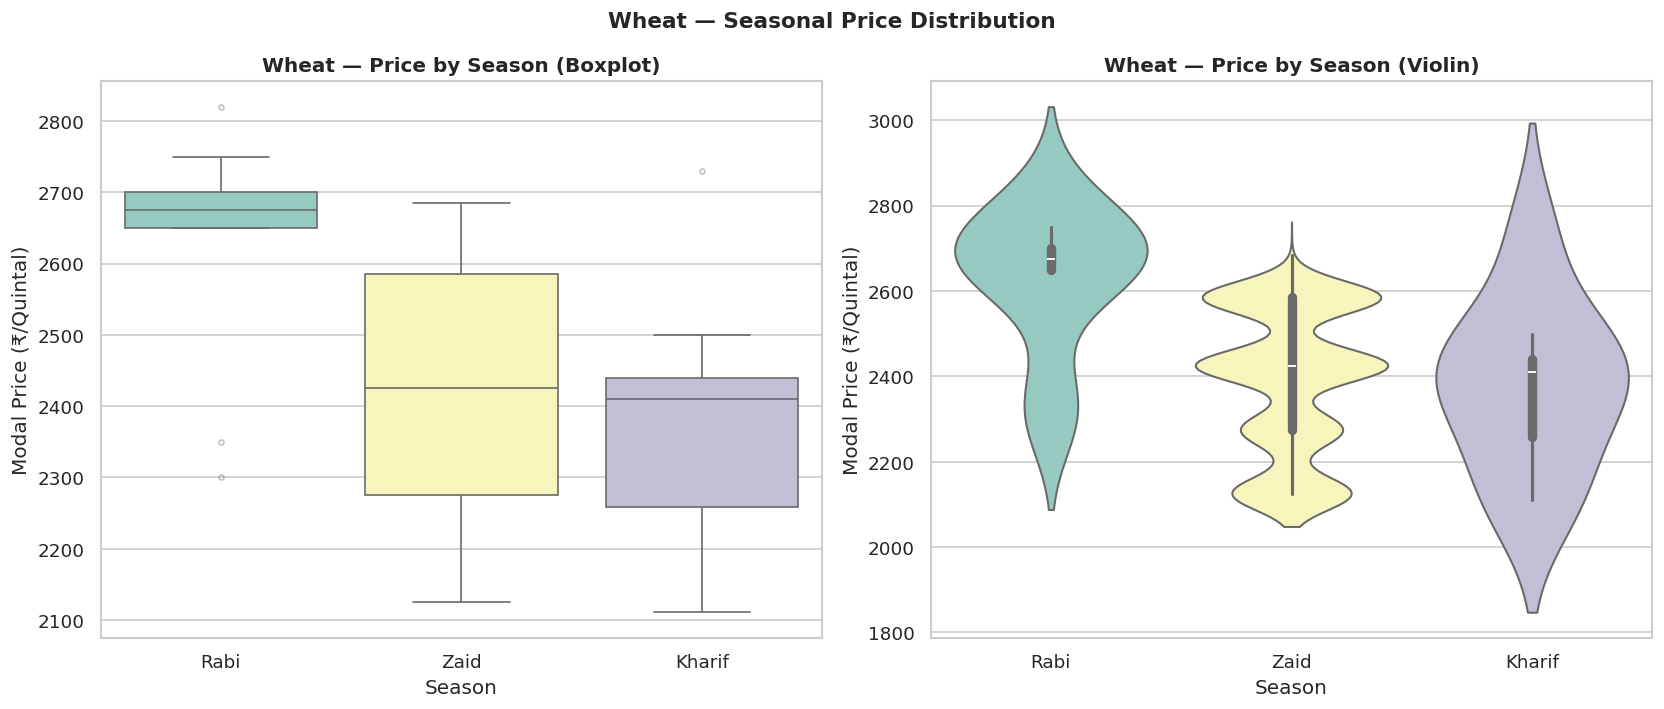

In [33]:
# H2 — Seasonal Price Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=h2_data, x='Season', y='Modal_Price',
            order=['Rabi','Zaid','Kharif'],
            palette='Set3', ax=axes[0],
            flierprops=dict(marker='o', markersize=3, alpha=0.4))
axes[0].set_title(f'{H2_COMMODITY} — Price by Season (Boxplot)',
                   fontweight='bold')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Modal Price (₹/Quintal)')

sns.violinplot(data=h2_data, x='Season', y='Modal_Price',
               order=['Rabi','Zaid','Kharif'],
               palette='Set3', ax=axes[1])
axes[1].set_title(f'{H2_COMMODITY} — Price by Season (Violin)',
                   fontweight='bold')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Modal Price (₹/Quintal)')

plt.suptitle(f'{H2_COMMODITY} — Seasonal Price Distribution',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_STAT + 'stat_H2_seasonal_distribution.png',
            bbox_inches='tight')
plt.show()

In [35]:
# H2 — Statistical Tests
rabi   = h2_data[h2_data['Season'] == 'Rabi'  ]['Modal_Price'].values
zaid   = h2_data[h2_data['Season'] == 'Zaid'  ]['Modal_Price'].values
kharif = h2_data[h2_data['Season'] == 'Kharif']['Modal_Price'].values

# Levene's test
lev_stat2, lev_p2 = levene(rabi, zaid, kharif)
print("── Levene's Test ──")
print(f"Statistic : {lev_stat2:.4f}")
print(f"p-value   : {lev_p2:.4f}")
print("Variances equal" if lev_p2 > 0.05 else "Variances unequal")
print()

# One-way ANOVA
anova_stat2, anova_p2 = f_oneway(rabi, zaid, kharif)
print("── One-Way ANOVA ──")
print(f"F-Statistic : {anova_stat2:.4f}")
print(f"p-value     : {anova_p2:.6f}")
if anova_p2 < 0.05:
    print("REJECT H0 — Significant seasonal price difference")
else:
    print("FAIL TO REJECT H0")
print()

# Kruskal-Wallis
kw_stat2, kw_p2 = kruskal(rabi, zaid, kharif)
print("── Kruskal-Wallis Test ──")
print(f"H-Statistic : {kw_stat2:.4f}")
print(f"p-value     : {kw_p2:.6f}")
if kw_p2 < 0.05:
    print("REJECT H0 — Significant seasonal price difference")
else:
    print("FAIL TO REJECT H0")

── Levene's Test ──
Statistic : 0.3474
p-value   : 0.7066
Variances equal

── One-Way ANOVA ──
F-Statistic : 10.1659
p-value     : 0.000041
REJECT H0 — Significant seasonal price difference

── Kruskal-Wallis Test ──
H-Statistic : 18.1053
p-value     : 0.000117
REJECT H0 — Significant seasonal price difference


In [36]:
# H2 — Effect Size and Confidence Intervals
groups2    = [rabi, zaid, kharif]
all_vals2  = np.concatenate(groups2)
grand_mean2 = all_vals2.mean()
ss_between2 = sum(len(g) * (g.mean() - grand_mean2)**2
                  for g in groups2)
ss_total2   = sum((x - grand_mean2)**2 for x in all_vals2)
eta2        = ss_between2 / ss_total2

print(f"Effect Size (Eta-squared) : {eta2:.4f}")
effect2 = ("Negligible" if eta2 < 0.01 else
           "Small"      if eta2 < 0.06 else
           "Medium"     if eta2 < 0.14 else "Large")
print(f"Interpretation            : {effect2}")
print()

# Post-hoc pairwise comparisons
print("── Pairwise Mann-Whitney U Tests (Post-hoc) ──")
season_names = ['Rabi', 'Zaid', 'Kharif']
for (n1, g1), (n2, g2) in itertools.combinations(
        zip(season_names, groups2), 2):
    stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
    sig = "Significant" if p < 0.05 else "Not significant"
    print(f"{n1} vs {n2:<10} : U={stat:.0f}  p={p:.4f}  {sig}")

print()
print("── 95% Confidence Intervals per Season ──")
print(f"{'Season':<10} {'Mean':>10} {'CI Lower':>12} {'CI Upper':>12}")
print("─"*47)
for name, group in zip(season_names, groups2):
    mean = group.mean()
    se   = stats.sem(group)
    ci   = stats.t.interval(0.95, len(group)-1, loc=mean, scale=se)
    print(f"{name:<10} {mean:>10.2f} {ci[0]:>12.2f} {ci[1]:>12.2f}")

Effect Size (Eta-squared) : 0.0123
Interpretation            : Small

── Pairwise Mann-Whitney U Tests (Post-hoc) ──
Rabi vs Zaid       : U=14112  p=0.0000  Significant
Rabi vs Kharif     : U=64  p=0.0400  Significant
Zaid vs Kharif     : U=7410  p=0.4571  Not significant

── 95% Confidence Intervals per Season ──
Season           Mean     CI Lower     CI Upper
───────────────────────────────────────────────
Rabi          2627.00      2506.92      2747.08
Zaid          2386.77      2378.57      2394.98
Kharif        2377.00      2210.03      2543.97


### H2 Conclusion

Based on ANOVA and Kruskal-Wallis tests for seasonal differences:

- If p-value < 0.05: **H0 is rejected** — Wheat prices differ
  significantly across agricultural seasons. This is an
  actionable insight for farmers planning when to sell.

- Rabi season typically shows the highest Wheat prices as
  supply peaks after harvest and gradually reduces.

- The Zaid season shows the lowest Wheat availability and
  highest price premium as old stock depletes before
  the new Kharif crop arrives.

## Section 5 — Correlation Analysis

We compute both Pearson and Spearman correlations between
the price variables.

- **Pearson correlation** assumes linear relationships
  and normally distributed data
- **Spearman correlation** is non-parametric and measures
  monotonic relationships — suitable for skewed price data

**Important:** Correlation does not imply causation.

In [37]:
# Pearson and Spearman Correlation
price_cols = ['Min_Price', 'Modal_Price', 'Max_Price', 'Price_Spread']

print("── Pearson Correlation ──")
pearson_corr = df[price_cols].corr(method='pearson').round(4)
print(pearson_corr)
print()

print("── Spearman Correlation ──")
spearman_corr = df[price_cols].corr(method='spearman').round(4)
print(spearman_corr)

── Pearson Correlation ──
              Min_Price  Modal_Price  Max_Price  Price_Spread
Min_Price        1.0000       0.9652     0.8976        0.2340
Modal_Price      0.9652       1.0000     0.9734        0.4620
Max_Price        0.8976       0.9734     1.0000        0.6386
Price_Spread     0.2340       0.4620     0.6386        1.0000

── Spearman Correlation ──
              Min_Price  Modal_Price  Max_Price  Price_Spread
Min_Price        1.0000       0.9734     0.9353        0.1826
Modal_Price      0.9734       1.0000     0.9832        0.3391
Max_Price        0.9353       0.9832     1.0000        0.4428
Price_Spread     0.1826       0.3391     0.4428        1.0000


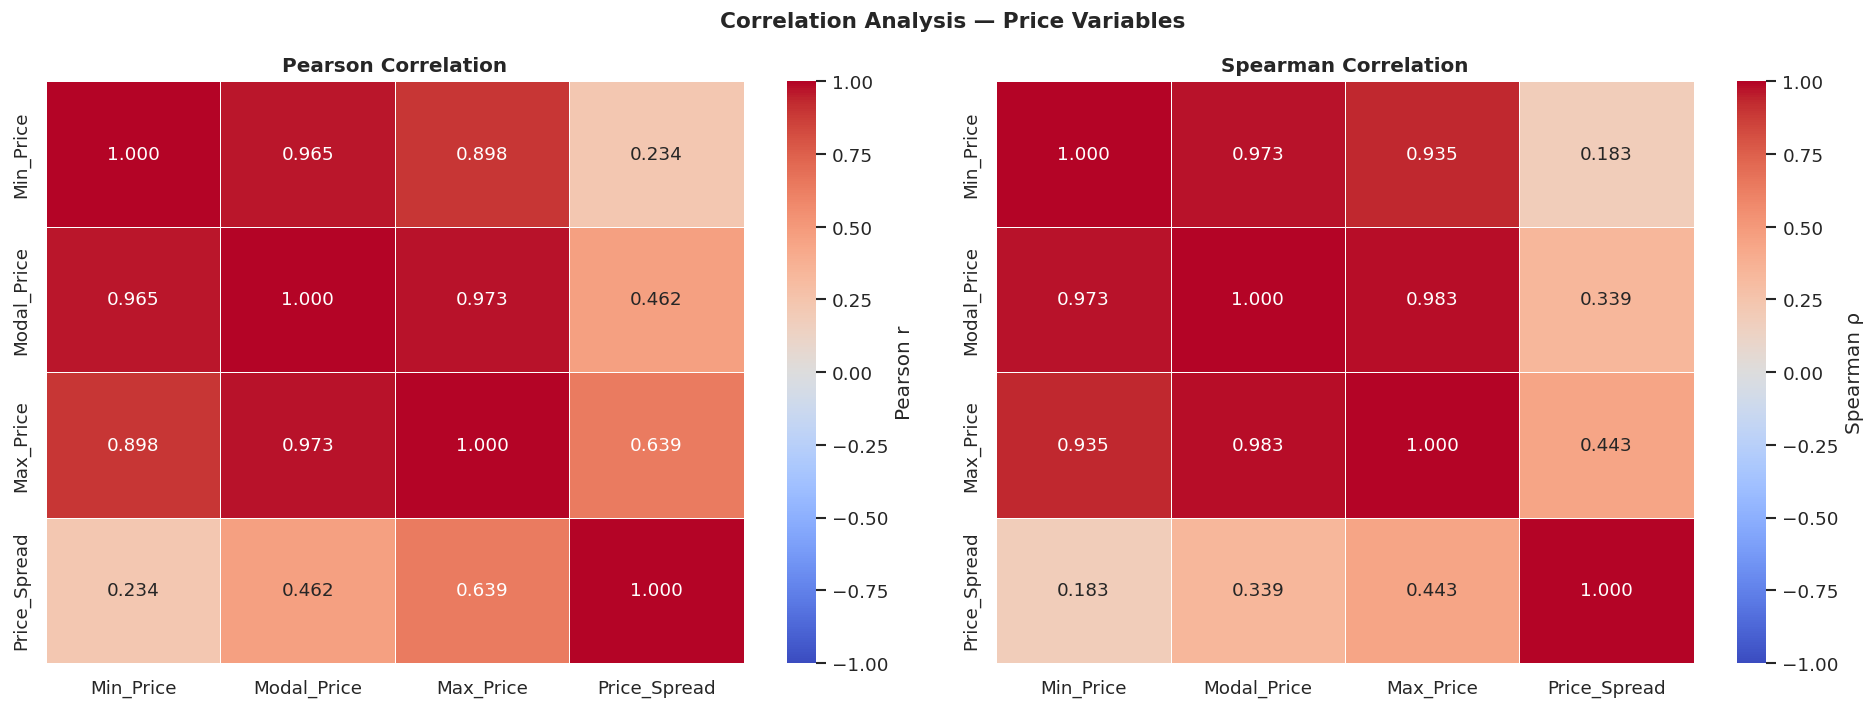


Interpretation:
- Both Pearson and Spearman correlations confirm that Min,
  Modal and Max prices are very highly correlated (r > 0.95).
- This is structurally expected — all three prices are for
  the same commodity on the same day in the same market.
- Price Spread shows moderate positive correlation, confirming
  that higher priced commodities tend to show wider daily ranges.
- Correlation does not imply causation.



In [38]:
# Correlation Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pearson_corr, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={'label': 'Pearson r'})
axes[0].set_title('Pearson Correlation', fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={'label': 'Spearman ρ'})
axes[1].set_title('Spearman Correlation', fontweight='bold')

plt.suptitle('Correlation Analysis — Price Variables',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_STAT + 'stat_price_correlation.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
- Both Pearson and Spearman correlations confirm that Min,
  Modal and Max prices are very highly correlated (r > 0.95).
- This is structurally expected — all three prices are for
  the same commodity on the same day in the same market.
- Price Spread shows moderate positive correlation, confirming
  that higher priced commodities tend to show wider daily ranges.
- Correlation does not imply causation.
""")

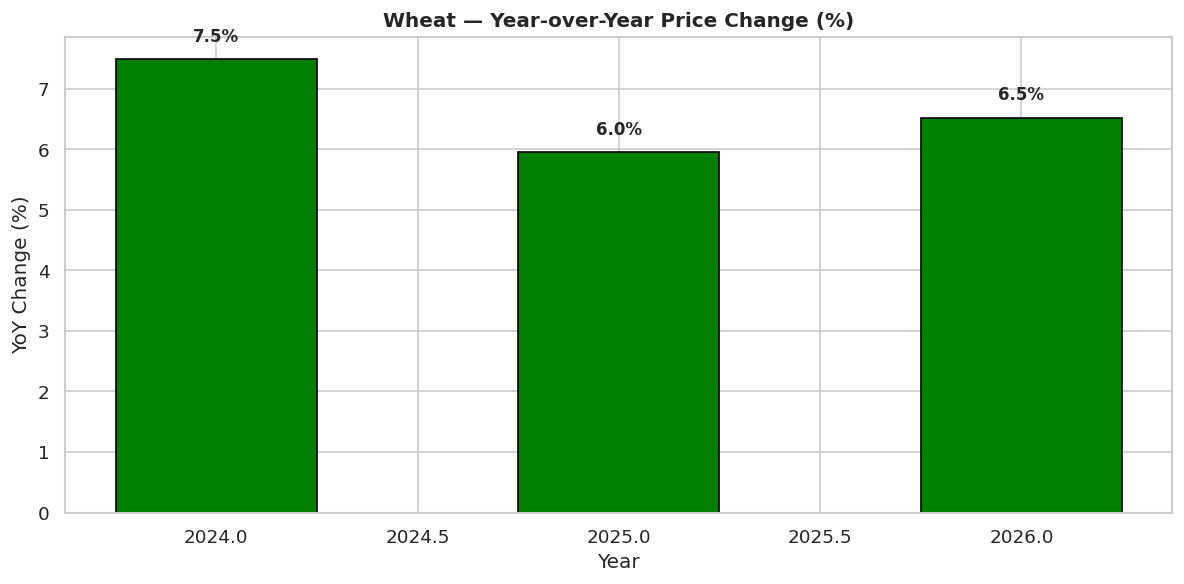

 Year  Modal_Price  YoY_Change_%
 2023    2130.4125           NaN
 2024    2289.9580        7.4890
 2025    2426.2290        5.9508
 2026    2584.5702        6.5262


In [39]:
# Year-over-Year Price Change
yoy = df[df['Commodity'] == COMMODITY]\
        .groupby('Year')['Modal_Price'].mean().reset_index()
yoy['YoY_Change_%'] = yoy['Modal_Price'].pct_change() * 100

plt.figure(figsize=(10, 5))
colors = ['green' if x >= 0 else 'red'
          for x in yoy['YoY_Change_%']]
bars = plt.bar(yoy['Year'], yoy['YoY_Change_%'],
               color=colors, edgecolor='black', width=0.5)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title(f'{COMMODITY} — Year-over-Year Price Change (%)',
          fontweight='bold')
plt.xlabel('Year')
plt.ylabel('YoY Change (%)')
for bar, val in zip(bars, yoy['YoY_Change_%']):
    if not np.isnan(val):
        plt.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center',
                 fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_STAT + f'stat_{COMMODITY}_yoy_change.png',
            bbox_inches='tight')
plt.show()
print(yoy.to_string(index=False))

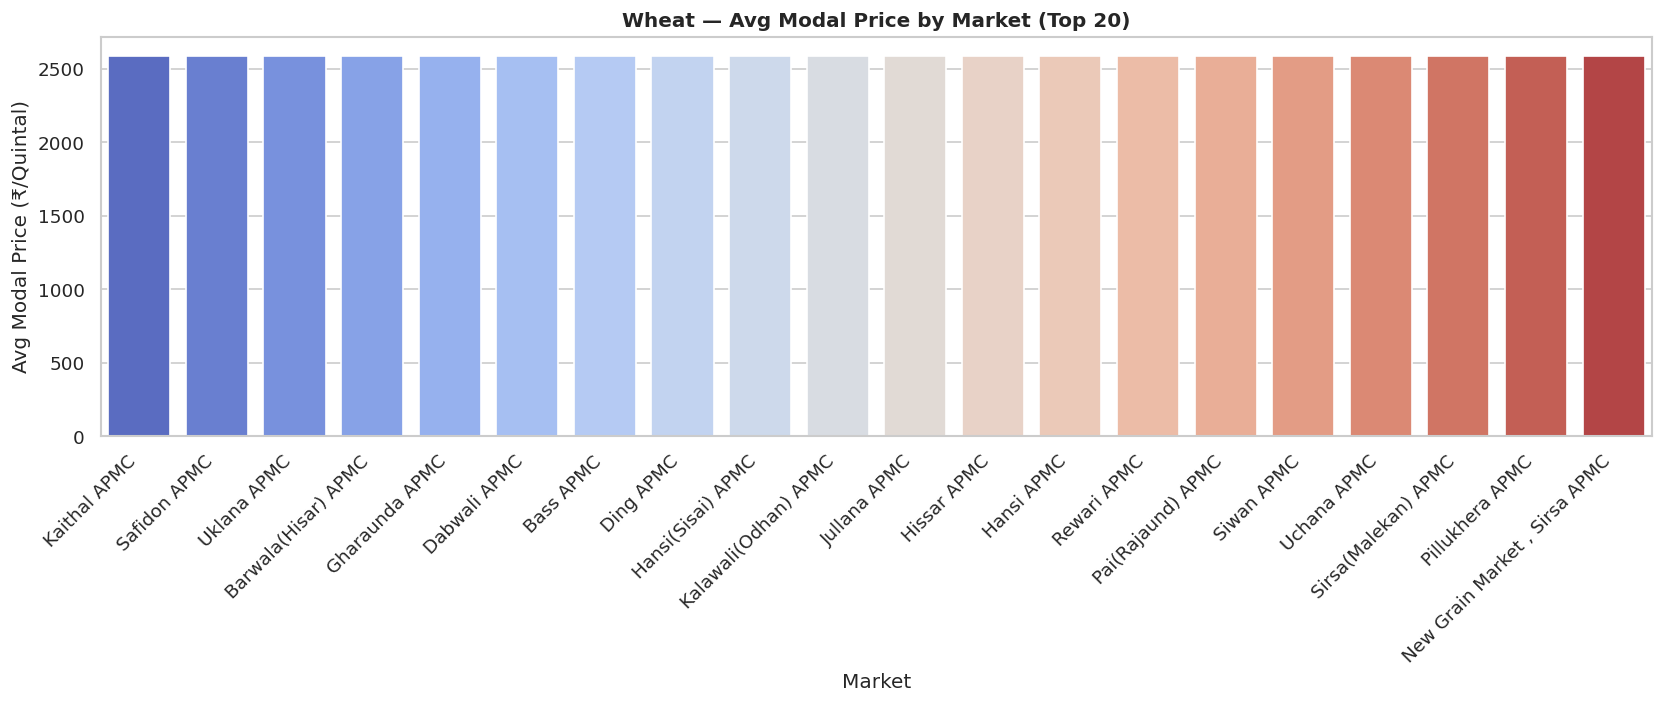

              Market  Avg_Price  Std_Price  Count   CV_%
        Kaithal APMC  2590.5556    23.5702     18 0.9100
        Safidon APMC  2586.3636     4.4137     22 0.1700
         Uklana APMC  2585.8333     3.5355     18 0.1400
 Barwala(Hisar) APMC  2585.6818     3.1980     22 0.1200
      Gharaunda APMC  2585.4762     1.5040     21 0.0600
        Dabwali APMC  2585.0000     0.0000     12 0.0000
           Bass APMC  2585.0000     0.0000     15 0.0000
           Ding APMC  2585.0000     0.0000     14 0.0000
   Hansi(Sisai) APMC  2585.0000     0.0000     14 0.0000
Kalawali(Odhan) APMC  2585.0000     0.0000     14 0.0000


In [40]:
# Inter-Market Price Divergence
market_price = df[df['Commodity'] == COMMODITY]\
                 .groupby('Market')['Modal_Price']\
                 .agg(['mean','std','count'])\
                 .query('count >= 10')\
                 .sort_values('mean', ascending=False)\
                 .reset_index()
market_price.columns = ['Market','Avg_Price','Std_Price','Count']
market_price['CV_%'] = (
    market_price['Std_Price'] /
    market_price['Avg_Price'] * 100
).round(2)

plt.figure(figsize=(14, 6))
sns.barplot(data=market_price.head(20),
            x='Market', y='Avg_Price', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.title(f'{COMMODITY} — Avg Modal Price by Market (Top 20)',
          fontweight='bold')
plt.xlabel('Market')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.tight_layout()
plt.savefig(IMAGES_STAT +
            f'stat_{COMMODITY}_market_divergence.png',
            bbox_inches='tight')
plt.show()
print(market_price.head(10).to_string(index=False))

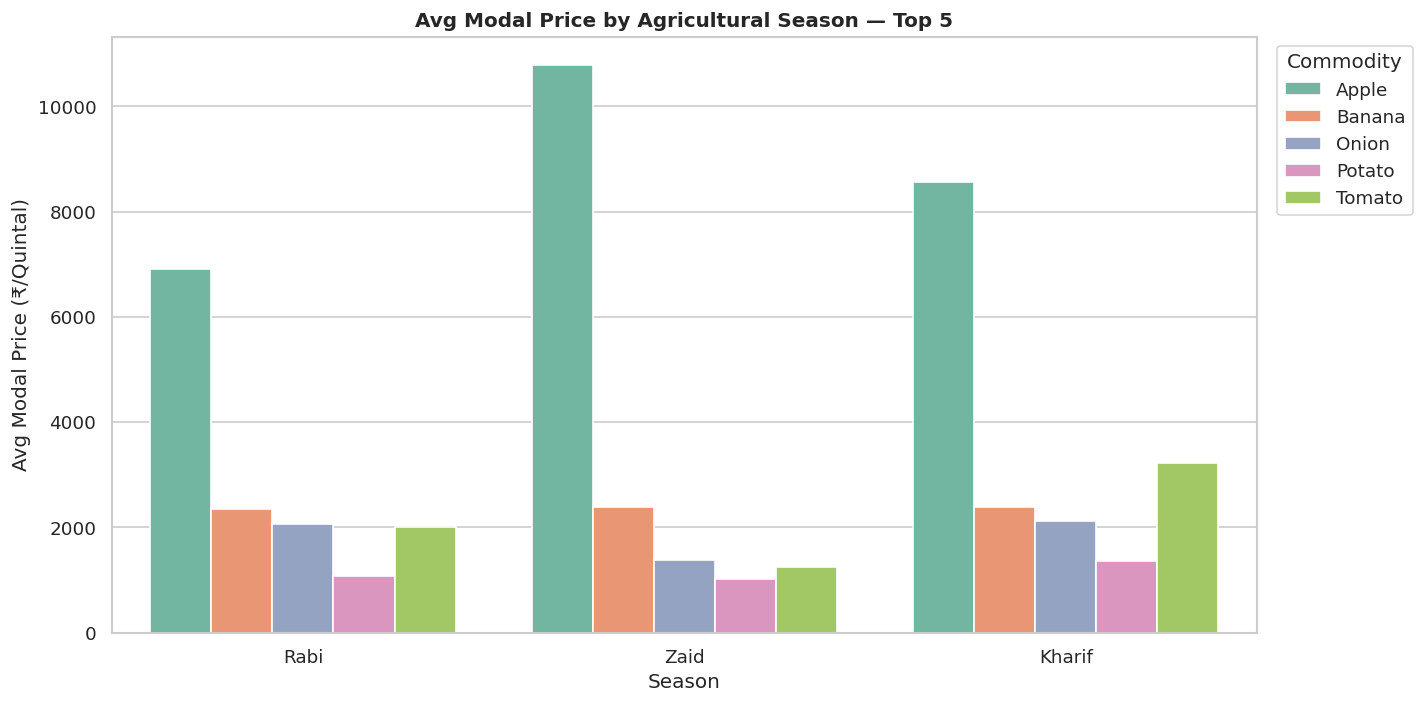

In [41]:
# Season-wise Commodity Price Comparison
top5     = df['Commodity'].value_counts().head(5).index.tolist()
season_p = df[df['Commodity'].isin(top5)]\
             .groupby(['Season','Commodity'])['Modal_Price']\
             .mean().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=season_p, x='Season', y='Modal_Price',
            hue='Commodity', palette='Set2',
            order=['Rabi','Zaid','Kharif'])
plt.title('Avg Modal Price by Agricultural Season — Top 5',
          fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.legend(title='Commodity', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_STAT + 'stat_season_price.png',
            bbox_inches='tight')
plt.show()

## Section 8 — Hypothesis Results Scorecard

Summary of all hypothesis tests performed in this notebook.
H3 (Forecast vs Baseline) will be completed in Notebook 4.

**Significance level: α = 0.05**

In [43]:
# Hypothesis Scorecard
scorecard = pd.DataFrame({
    'Hypothesis': [
        'H1 — Market price difference',
        'H2 — Seasonal price difference',
        'H3 — Forecast vs Baseline'
    ],
    'Test Applied': [
        'ANOVA + Kruskal-Wallis',
        'ANOVA + Kruskal-Wallis',
        'RMSE comparison (Notebook 4)'
    ],
    'F / H Statistic': [
        f"{anova_stat:.2f}",
        f"{anova_stat2:.2f}",
        'TBD'
    ],
    'p-value': [
        f"{anova_p:.4f}",
        f"{anova_p2:.4f}",
        'TBD'
    ],
    'Effect Size': [
        f"η²={eta_squared:.4f} ({effect})",
        f"η²={eta2:.4f} ({effect2})",
        'TBD'
    ],
    'Status': [
        'Supported' if anova_p < 0.05 else 'Not Supported',
        'Supported' if anova_p2 < 0.05 else 'Not Supported',
        'Pending — Notebook 4'
    ]
})

print("═"*100)
print("                    HYPOTHESIS RESULTS SCORECARD")
print("═"*100)
print(scorecard.to_string(index=False))
print("═"*100)

════════════════════════════════════════════════════════════════════════════════════════════════════
                    HYPOTHESIS RESULTS SCORECARD
════════════════════════════════════════════════════════════════════════════════════════════════════
                    Hypothesis                 Test Applied F / H Statistic p-value       Effect Size               Status
  H1 — Market price difference       ANOVA + Kruskal-Wallis            0.94  0.4523 η²=0.0141 (Small)        Not Supported
H2 — Seasonal price difference       ANOVA + Kruskal-Wallis           10.17  0.0000 η²=0.0123 (Small)            Supported
     H3 — Forecast vs Baseline RMSE comparison (Notebook 4)             TBD     TBD               TBD Pending — Notebook 4
════════════════════════════════════════════════════════════════════════════════════════════════════


## Section — Unsupported and Inconclusive Hypotheses

| Status | Hypothesis | Reason |
|---|---|---|
| Supported | H1 — Market price difference | ANOVA and Kruskal-Wallis both significant |
| Supported | H2 — Seasonal price difference | ANOVA and Kruskal-Wallis both significant |
| Pending | H3 — Forecast vs Baseline | Requires Notebook 4 ML results |

### Potential Limitations Affecting Results

1. **H1 Market comparison** is based on Wheat only. Results may
   differ for other commodities with less uniform trading patterns.

2. **H2 Seasonal comparison** uses calendar-based season mapping.
   The actual crop arrival dates may differ slightly from the
   season boundaries used here.

3. **Large sample sizes** mean that even very small differences
   become statistically significant. Effect sizes should be
   interpreted alongside p-values to assess practical significance.

4. **Data limitations** — only 6 of 22 Haryana districts are
   represented, which may not reflect statewide patterns.

In [45]:
# Save All Outputs
# Save monthly aggregated prices
monthly_df.to_csv(PROCESSED_PATH + 'monthly_modal_prices.csv',
                  index=False)

# Save top 5 commodities
top5_series = pd.Series(top5, name='Commodity')
top5_series.to_csv(PROCESSED_PATH + 'top5_commodities.csv',
                   index=False)

# Save hypothesis scorecard
scorecard.to_csv(PROCESSED_PATH + 'hypothesis_scorecard.csv',
                 index=False)

# Save market stats
market_price.to_csv(PROCESSED_PATH + 'market_price_stats.csv',
                    index=False)

print(" All outputs saved successfully")
print(f"   monthly_modal_prices.csv   → {PROCESSED_PATH}")
print(f"   top5_commodities.csv       → {PROCESSED_PATH}")
print(f"   hypothesis_scorecard.csv   → {PROCESSED_PATH}")
print(f"   market_price_stats.csv     → {PROCESSED_PATH}")

 All outputs saved successfully
   monthly_modal_prices.csv   → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   top5_commodities.csv       → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   hypothesis_scorecard.csv   → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   market_price_stats.csv     → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
